In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product

from enums import Stock, PutCallFwd, LongShort, GreekMethod, FiniteDifferenceMethod, BumpType
from contract import EuropeanContract
from market_data import MarketData, VolGrid
from model import BSVolModel, FlatVolModel
from pricer import EuropeanAnalyticPricer, Params

In [2]:
MarketData.risk_free_rate = 0.05

MarketData.spot = {
    Stock.BLUECHIP_BANK: 130.17,
    Stock.TIPTOP_SOLUTIONS: 177.32,
}

volatilities = {
    Stock.BLUECHIP_BANK: 0.381,
    Stock.TIPTOP_SOLUTIONS: 0.320,
}

MarketData.volgrid = {}

for underlying, spot in MarketData.spot.items():
    points = np.array([
        (0.5 * spot, 0.1),
        (1.5 * spot, 0.1),
        (0.5 * spot, 3.0),
        (1.5 * spot, 3.0),
    ])

    values = np.full(len(points), volatilities[underlying])

    MarketData.volgrid[underlying] = VolGrid(
        underlying, points, values
    )

MarketData.is_initialized = True

print("Synthetic market data initialized:", list(MarketData.spot))

Synthetic market data initialized: [<Stock.BLUECHIP_BANK: 'BLUECHIP_BANK'>, <Stock.TIPTOP_SOLUTIONS: 'TIPTOP_SOLUTIONS'>]


In [3]:
contracts = []

for underlying, derivative_type, strike_ratio, expiry in product(
    MarketData.spot,
    (PutCallFwd.CALL, PutCallFwd.PUT),
    (0.9, 1.0, 1.1),
    (0.25, 1.0, 2.0),
):
    contracts.append(EuropeanContract(
        underlying=underlying,
        derivative_type=derivative_type,
        long_short=LongShort.LONG,
        strike=MarketData.spot[underlying] * strike_ratio,
        expiry=expiry,
    ))

print(f"Number of European options: {len(contracts)}")

# calculate analytic Greeks for example contract

example = contracts[0]

pricer = EuropeanAnalyticPricer(
    example,
    FlatVolModel(example.underlying),
    Params()
)

print("Fair value:", pricer.calc_fair_value())
print("Analytic Delta:", pricer.calc_delta(GreekMethod.ANALYTIC))
print("Analytic Gamma:", pricer.calc_gamma(GreekMethod.ANALYTIC))

Number of European options: 36
Fair value: 18.28768128334599
Analytic Delta: 0.762367973847413
Analytic Gamma: 0.012468720087738631


In [4]:
rows = []

for fd_method, bump_type in product(
    FiniteDifferenceMethod, BumpType
):
    pricer.finite_difference_method = fd_method
    pricer.bump_type = bump_type

    # use the same actual bump size for both bump types
    pricer.relative_bump_size = 0.001
    pricer.absolute_bump_size = 0.001 * pricer.model.spot

    rows.append({
        "difference": fd_method.value,
        "bump": bump_type.value,
        "delta": pricer.calc_delta(GreekMethod.BUMP),
        "gamma": pricer.calc_gamma(GreekMethod.BUMP),
    })

comparison = pd.DataFrame(rows)

print(comparison.to_string(index=False))

difference     bump    delta    gamma
   FORWARD ABSOLUTE 0.763178 0.012410
   FORWARD RELATIVE 0.763178 0.012410
  BACKWARD ABSOLUTE 0.761555 0.012528
  BACKWARD RELATIVE 0.761555 0.012528
   CENTRAL ABSOLUTE 0.762367 0.012469
   CENTRAL RELATIVE 0.762367 0.012469


In [5]:
scales = np.logspace(-6, -1, 13)
results = []

for contract in contracts:
    p = EuropeanAnalyticPricer(
        contract,
        FlatVolModel(contract.underlying),
        Params()
    )

    reference = {
        "Delta": p.calc_delta(GreekMethod.ANALYTIC),
        "Gamma": p.calc_gamma(GreekMethod.ANALYTIC),
    }

    for fd_method, bump_type, scale in product(
        FiniteDifferenceMethod, BumpType, scales
    ):
        p.finite_difference_method = fd_method
        p.bump_type = bump_type

        p.relative_bump_size = scale
        p.absolute_bump_size = 100.0 * scale

        for greek in ("Delta", "Gamma"):
            if greek == "Delta":
                numeric = p.calc_delta(GreekMethod.BUMP)
            else:
                numeric = p.calc_gamma(GreekMethod.BUMP)

            results.append({
                "greek": greek,
                "difference": fd_method.value,
                "bump": bump_type.value,
                "scale": float(scale),
                "error": abs(numeric - reference[greek]),
            })

errors = pd.DataFrame(results)

mean_errors = errors.groupby(
    ["greek", "difference", "bump", "scale"],
    as_index=False
)["error"].mean()

print(f"Total comparisons: {len(errors)}")
print(f"Average error data points: {len(mean_errors)}")

Total comparisons: 5616
Average error data points: 156


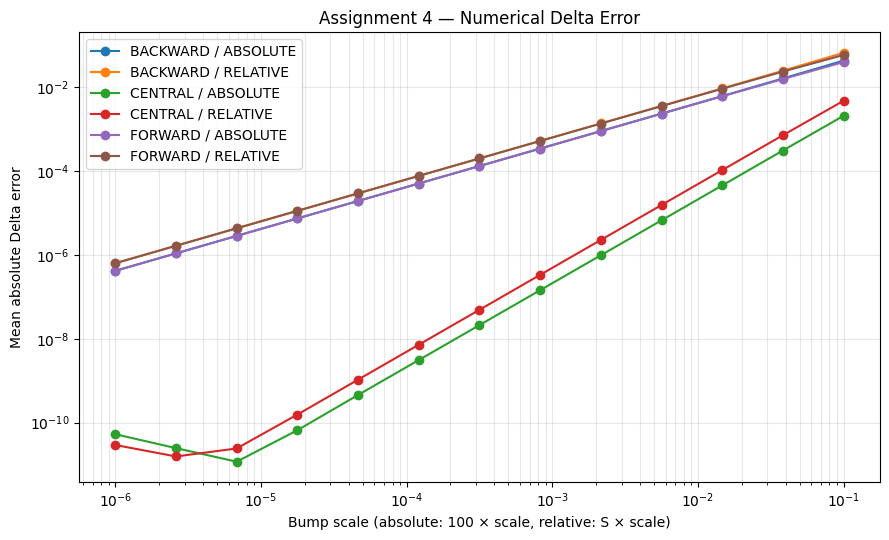

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.5))

delta_errors = mean_errors.query("greek == 'Delta'")

for (fd, bump), part in delta_errors.groupby(
    ["difference", "bump"]
):
    ax.loglog(
        part["scale"],
        part["error"],
        marker="o",
        label=f"{fd} / {bump}"
    )

ax.set(
    xlabel="Bump scale (absolute: 100 × scale, relative: S × scale)",
    ylabel="Mean absolute Delta error",
    title="Assignment 4 — Numerical Delta Error"
)

ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

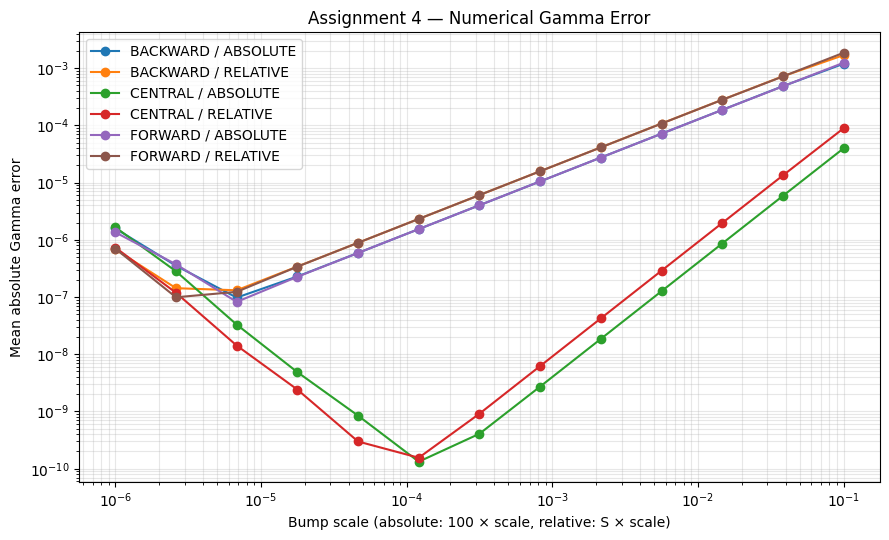

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))

gamma_errors = mean_errors.query("greek == 'Gamma'")

for (fd, bump), part in gamma_errors.groupby(
    ["difference", "bump"]
):
    ax.loglog(
        part["scale"],
        part["error"],
        marker="o",
        label=f"{fd} / {bump}"
    )

ax.set(
    xlabel="Bump scale (absolute: 100 × scale, relative: S × scale)",
    ylabel="Mean absolute Gamma error",
    title="Assignment 4 — Numerical Gamma Error"
)

ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
best = mean_errors.loc[
    mean_errors.groupby(
        ["greek", "difference", "bump"]
    )["error"].idxmin()
].sort_values(
    ["greek", "difference", "bump"]
)

print(best.to_string(
    index=False,
    formatters={
        "scale": "{:.2e}".format,
        "error": "{:.3e}".format
    }
))

# Identify the best configuration for each Greek.

for greek in ("Delta", "Gamma"):
    row = best.query(
        "greek == @greek"
    ).sort_values("error").iloc[0]

    print(
        f"{greek}: "
        f"Best method = {row['difference']}, "
        f"Bump type = {row['bump']}, "
        f"Optimal tested scale = {row['scale']:.2e}, "
        f"Mean absolute error = {row['error']:.3e}"
    )

greek difference     bump    scale     error
Delta   BACKWARD ABSOLUTE 1.00e-06 4.182e-07
Delta   BACKWARD RELATIVE 1.00e-06 6.354e-07
Delta    CENTRAL ABSOLUTE 6.81e-06 1.170e-11
Delta    CENTRAL RELATIVE 2.61e-06 1.558e-11
Delta    FORWARD ABSOLUTE 1.00e-06 4.182e-07
Delta    FORWARD RELATIVE 1.00e-06 6.354e-07
Gamma   BACKWARD ABSOLUTE 6.81e-06 9.777e-08
Gamma   BACKWARD RELATIVE 6.81e-06 1.313e-07
Gamma    CENTRAL ABSOLUTE 1.21e-04 1.327e-10
Gamma    CENTRAL RELATIVE 1.21e-04 1.555e-10
Gamma    FORWARD ABSOLUTE 6.81e-06 8.229e-08
Gamma    FORWARD RELATIVE 2.61e-06 9.907e-08
Delta: Best method = CENTRAL, Bump type = ABSOLUTE, Optimal tested scale = 6.81e-06, Mean absolute error = 1.170e-11
Gamma: Best method = CENTRAL, Bump type = ABSOLUTE, Optimal tested scale = 1.21e-04, Mean absolute error = 1.327e-10


In [9]:
for contract in contracts:
    p = EuropeanAnalyticPricer(
        contract,
        FlatVolModel(contract.underlying),
        Params()
    )

    p.finite_difference_method = FiniteDifferenceMethod.CENTRAL

    for bump in BumpType:
        p.bump_type = bump
        p.relative_bump_size = 1e-4
        p.absolute_bump_size = p.model.spot * 1e-4

        analytic_delta = p.calc_delta(GreekMethod.ANALYTIC)
        numeric_delta = p.calc_delta(GreekMethod.BUMP)

        analytic_gamma = p.calc_gamma(GreekMethod.ANALYTIC)
        numeric_gamma = p.calc_gamma(GreekMethod.BUMP)

        assert abs(numeric_delta - analytic_delta) < 1e-6
        assert abs(numeric_gamma - analytic_gamma) < 1e-6

print("All numerical Delta and Gamma validation tests passed.")

All numerical Delta and Gamma validation tests passed.
